# Project 03 · Neural Network & Backpropagation: Mortgage Delinquency

**Track:** Deep Learning  
**Research / product question:** Can a hand-built MLP learn nonlinear mortgage default risk better than logistic regression?

**Learning outcome:** Implement 2-layer neural network gradients in NumPy and compare to calibrated baselines.

**Workflow:** Data-generating process → raw-data audit → leakage-safe features → from-scratch baseline → model selection / hyperparameter tuning → held-out evaluation → failure analysis.

> **Synthetic-data disclosure:** All records and outcomes are created in this notebook; they do not describe real customers or credit decisions. Ground truth is constructed for teaching. Numerical results are illustrative of this simulator, not estimates of real-world business impact.

**Reproducibility:** Random seeds are fixed. Run cells top-to-bottom. Install packages from the project-level `requirements.txt`. CPU execution is supported; deep-learning examples deliberately use small models.

> **Portfolio standard:** fully reproducible, synthetic educational data · explicit evaluation protocol · plots and failure analysis · no claims of production accuracy.

The MLP implements gradients in NumPy; PyTorch is not needed for backprop. Compare against simple logistic regression and a non-neural tabular baseline on the same held-out set.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
SEED = 42
rng = np.random.default_rng(SEED)
plt.rcParams.update({'figure.figsize': (8, 4), 'axes.grid': True, 'grid.alpha': 0.2})

## 1. Simulate borrower features and nonlinear risk

This dataset has interactions between debt burden, credit, LTV and an unemployment shock. Unlike real credit datasets, it is freely reproducible and contains no identifiable borrowers.

In [2]:
# Nonlinear borrower risk is generated with known signal and noise.
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import average_precision_score, roc_auc_score, precision_recall_curve
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
n=3600
credit=np.clip(rng.normal(700,65,n),490,845);dti=np.clip(rng.normal(.36,.10,n),.08,.75)
ltv=np.clip(rng.normal(.80,.12,n),.4,1.08);unemp=rng.binomial(1,.10,n);rate=rng.normal(6.4,.85,n)
income=np.exp(rng.normal(10.9,.42,n))
logit=-3.3-1.1*(credit-700)/75+1.2*(dti-.36)/.14+1.1*(ltv-.8)/.14+1.05*unemp+.75*(dti>.47)*(ltv>.90)+.25*(rate-6)
truth=1/(1+np.exp(-logit));y=rng.binomial(1,truth)
frame=pd.DataFrame({'credit_score':credit,'dti':dti,'ltv':ltv,'unemployed':unemp,'rate':rate,'log_income':np.log(income),'delinquent':y})
cols=[c for c in frame if c!='delinquent'];a,b=train_test_split(np.arange(n),test_size=.4,stratify=y,random_state=42);v,t=train_test_split(b,test_size=.5,stratify=y[b],random_state=42)
sc=StandardScaler().fit(frame.loc[a,cols]);Xtr=sc.transform(frame.loc[a,cols]);Xva=sc.transform(frame.loc[v,cols]);Xte=sc.transform(frame.loc[t,cols]);ytr=y[a];yva=y[v];yte=y[t]
print('Sample sizes',len(a),len(v),len(t),'Event rate',round(y.mean(),3));print(frame.describe().round(2).to_string())

Sample sizes 2160 720 720 Event rate 0.098
       credit_score      dti      ltv  unemployed     rate  log_income  delinquent
count       3600.00  3600.00  3600.00     3600.00  3600.00     3600.00      3600.0
mean         698.70     0.36     0.80        0.10     6.43       10.92         0.1
std           64.28     0.10     0.12        0.29     0.85        0.43         0.3
min          490.00     0.08     0.40        0.00     3.63        9.35         0.0
25%          655.83     0.29     0.72        0.00     5.86       10.62         0.0
50%          700.53     0.36     0.79        0.00     6.41       10.91         0.0
75%          741.70     0.43     0.88        0.00     7.00       11.20         0.0
max          845.00     0.71     1.08        1.00     9.12       12.39         1.0


## 2. Write the MLP forward/backward pass in NumPy

For a sigmoid binary classifier with cross-entropy, the output-layer gradient simplifies to `(p-y)/n`. Hidden-layer gradients follow the chain rule. No automatic differentiation is used.

In [3]:
# Manual NumPy forward/backward; no autograd for these gradients.
def sig(z):return 1/(1+np.exp(-np.clip(z,-25,25)))
class ManualMLP:
 def __init__(self,features,hidden=12,lr=.05,l2=.0005,seed=3):
    self.lr=lr;self.l2=l2;r=np.random.default_rng(seed)
    self.W1=r.normal(0,np.sqrt(2/features),(features,hidden));self.b1=np.zeros(hidden)
    self.W2=r.normal(0,1/np.sqrt(hidden),(hidden,1));self.b2=np.zeros(1)
 def predict(self,X):
    h=np.tanh(X@self.W1+self.b1)
    return sig((h@self.W2+self.b2).ravel())
 def train(self,X,y,epochs=180,batch=256):
    trace=[];r=np.random.default_rng(7);n=len(y)
    for e in range(epochs):
      for ix in np.array_split(r.permutation(n),max(1,int(np.ceil(n/batch)))):
        a=X[ix];target=y[ix];h=np.tanh(a@self.W1+self.b1);p=sig((h@self.W2+self.b2).ravel());m=len(ix)
        d2=(p-target)[:,None]/m
        gW2=h.T@d2+self.l2*self.W2;gb2=d2.sum(axis=0)
        d1=(d2@self.W2.T)*(1-h*h)
        gW1=a.T@d1+self.l2*self.W1;gb1=d1.sum(axis=0)
        self.W2-=self.lr*gW2;self.b2-=self.lr*gb2;self.W1-=self.lr*gW1;self.b1-=self.lr*gb1
      p=np.clip(self.predict(X),1e-7,1-1e-7)
      trace.append(-np.mean(y*np.log(p)+(1-y)*np.log(1-p)))
    return trace
# Verify gradient behavior by checking that training loss decreases.
toy=ManualMLP(Xtr.shape[1]);losses=toy.train(Xtr,ytr,epochs=60)
print('Initial → final training BCE:',round(losses[0],4),'→',round(losses[-1],4));assert losses[-1]<losses[0]

Initial → final training BCE: 0.7282 → 0.2359


## 3. Tune hidden width and learning rate

We choose models by validation **average precision**, not test performance. The network has few parameters so it can train on CPU.

Validation hyperparameter search: [(8, 0.025, 0.546), (8, 0.08, 0.568), (24, 0.025, 0.493), (24, 0.08, 0.513)]
Selected: (8, 0.08, 0.5681035438775642)


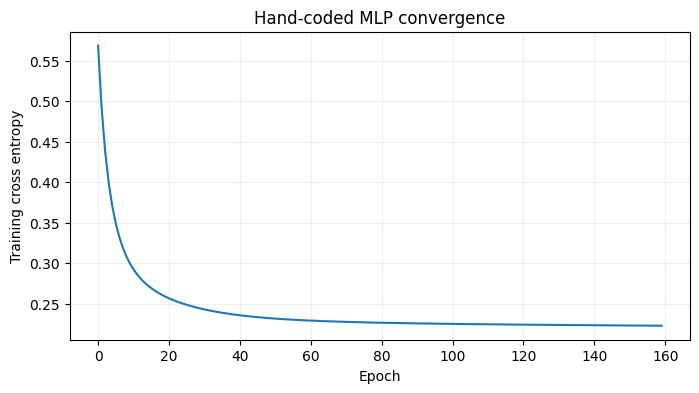

In [4]:
# Select hyperparameters only with a validation subset.
results=[];models={}
for h in [8,24]:
 for lr in [.025,.08]:
    m=ManualMLP(Xtr.shape[1],hidden=h,lr=lr);curve=m.train(Xtr,ytr,epochs=160)
    ap=average_precision_score(yva,m.predict(Xva));results.append((h,lr,ap));models[(h,lr)]=(m,curve)
best=max(results,key=lambda x:x[2]);net,trace=models[(best[0],best[1])]
print('Validation hyperparameter search:',[(h,lr,round(ap,3)) for h,lr,ap in results]);print('Selected:',best)
plt.plot(trace);plt.xlabel('Epoch');plt.ylabel('Training cross entropy');plt.title('Hand-coded MLP convergence');plt.show()

## 4. Held-out baselines and model evaluation

Compare the handwritten MLP against Logistic Regression and HistGradientBoosting on the same test set. No threshold is chosen using test labels.

Logistic AP 0.491 ROC-AUC 0.846
Manual MLP AP 0.483 ROC-AUC 0.853
Boosted trees AP 0.423 ROC-AUC 0.814


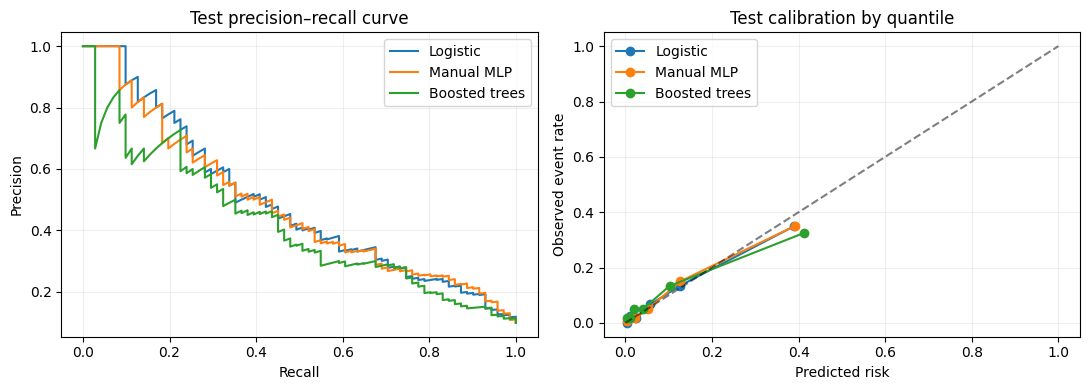

In [5]:
# Compare classical and neural baselines on the same test split.
logit=LogisticRegression(max_iter=300).fit(Xtr,ytr)
boost=HistGradientBoostingClassifier(max_iter=120,max_leaf_nodes=9,l2_regularization=5,random_state=42).fit(Xtr,ytr)
preds={'Logistic':logit.predict_proba(Xte)[:,1],'Manual MLP':net.predict(Xte),'Boosted trees':boost.predict_proba(Xte)[:,1]}
for name,p in preds.items():print(name,'AP',round(average_precision_score(yte,p),3),'ROC-AUC',round(roc_auc_score(yte,p),3))
fig,ax=plt.subplots(1,2,figsize=(11,4))
for name,p in preds.items():
    prec,rec,_=precision_recall_curve(yte,p);ax[0].plot(rec,prec,label=name)
ax[0].legend();ax[0].set(xlabel='Recall',ylabel='Precision',title='Test precision–recall curve')
for name,p in preds.items():
    breaks=np.quantile(p,np.linspace(0,1,7));bucket=np.digitize(p,breaks[1:-1]);xx=[p[bucket==i].mean() for i in range(6)];yy=[yte[bucket==i].mean() for i in range(6)];ax[1].plot(xx,yy,marker='o',label=name)
ax[1].plot([0,1],[0,1],'k--',alpha=.5);ax[1].set(xlabel='Predicted risk',ylabel='Observed event rate',title='Test calibration by quantile');ax[1].legend();plt.tight_layout();plt.show()

## What the results mean / interview discussion

The exact same covariates support an interpretable linear baseline, a manual differentiable network and a tree model. A nonlinear MLP is not automatically the winner on structured mortgage data. Carefully separated validation and test data are more important than ever-larger models.

**Try explaining these without looking at the code:**

1. Derive the sigmoid BCE gradient.
2. Why is average precision more useful than accuracy?
3. How would you validate this model across vintages and economic regimes?

**Limitations and next step:** Evaluate on a suitably licensed real-world dataset or stronger simulation with domain shift, logging bias and realistic selection. Never treat synthetic performance as production evidence.

## What this project demonstrates, and what it does not

**Next:** inspect calibration and fairness by subgroup, evaluate on a later origination vintage, and add class-imbalance-sensitive decision thresholds. Predicted delinquency is not causal.

**Reproduce:** `Run All` in Jupyter; no private or uploaded data required. For real data, use leakage-safe train/validation/test partitions and respect each dataset license.